# Классификация объектов на TensorFlow Lite для микроконтроллеров на Zephyr
### Подготовил: Степанюк Денис Борисович
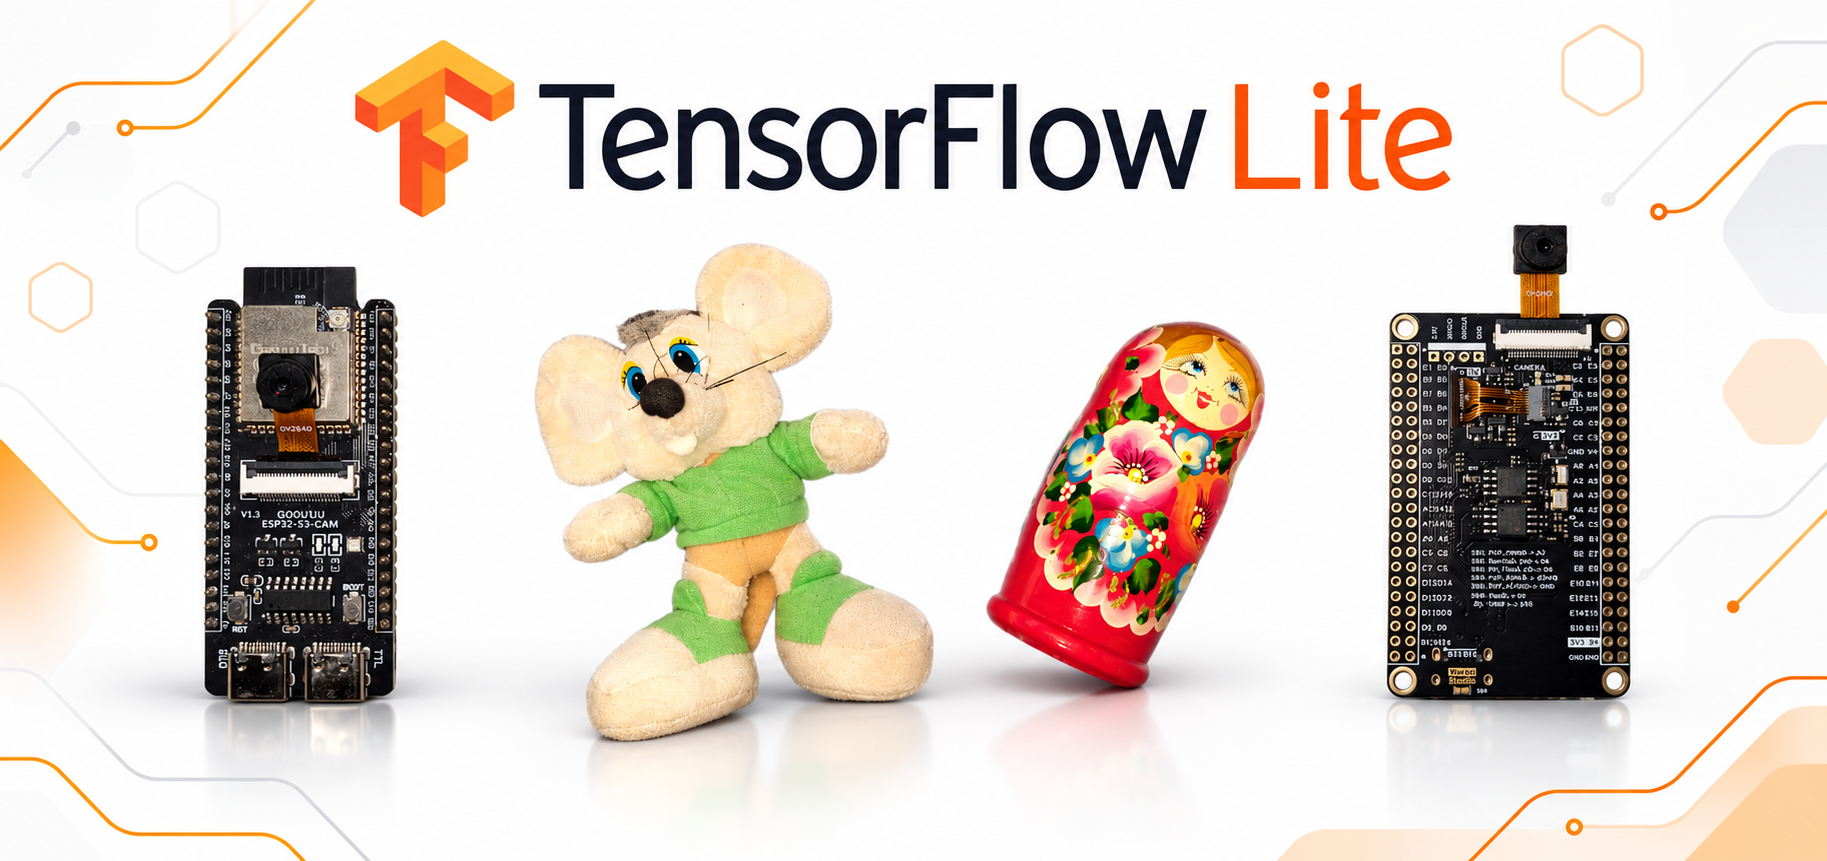

In [1]:
import os
import math
import json
import time
import warnings

import numpy as np
import PIL
from PIL import Image

import matplotlib.pyplot as plt

import keras
import tensorflow as tf

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import classification_report, confusion_matrix
from scipy.sparse.csgraph import connected_components

print("Keras     :", keras.__version__)
print("TensorFlow:", tf.__version__)
print("Устройства:", tf.config.list_physical_devices())

Keras     : 2.13.1
TensorFlow: 2.13.0
Устройства: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


# Конфигурация
Все настраиваемые параметры в проекте.

In [ ]:
# ----------------------------- Данные -----------------------------
# Путь к папкам с данными: по одной подпапке на класс. Изображения уже уменьшены ПЛАТОЙ до 32x32 (тем же алгоритмом, что и при инференсе).
TRAIN_DATASET_PATH=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\15_TFL_Classification_CNN\src\python\Datasets\Train_Dataset",
VAL_DATASET_PATH=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\15_TFL_Classification_CNN\src\python\Datasets\Validation_Dataset",
TEST_DATASET_PATH=r"\\wsl.localhost\Ubuntu\home\stepanjuk\zephyrproject\projects\final\15_TFL_Classification_CNN\src\python\Datasets\Test_Dataset",
# Размеры изображения (вход модели). Меняйте только вместе с прошивкой и датасетом.
IMAGE_HEIGHT = 32
IMAGE_WIDTH = 32
CHANNELS = 3

# ----------------------------- Аугментация -----------------------------
AUG_STRENGTH = 1.0       # общий множитель силы аугментации (0 - выключить, 1 - по умолчанию, 1.5 - сильнее)
ROT_DEG = 180            # максимальный угол поворота (±). Если объекты всегда лежат «прямо», уменьшите до 20-30.
FLIP_H = True            # случайное отражение по горизонтали
FLIP_V = True            # случайное отражение по вертикали
MIXUP_ALPHA = 0.0        # >0 включает mixup (например 0.2). Для очень маленьких сетей часто лучше оставить 0.

# ----------------------------- Обучение -----------------------------
BATCH_SIZE = 32
EPOCHS = 400
PEAK_LR = 3e-3
WARMUP_EPOCHS = 5
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.1
EARLY_STOP_PATIENCE = 60

# ----------------------------- Модель -----------------------------
# Пресеты ширины сети. Обучаются все из списка, затем выбирается один для экспорта.
# • stem - кол-во фильтров в первом (входном) свёрточном слое.
# • stages — список кол-ва фильтров для каждой стадии (уровня разрешения). Длина списка = число стадий.
# • blocks_per_stage — сколько подряд sep_block-ов ставится внутри каждой стадии.
PRESETS = {
    "small":   dict(stem=12, stages=[24, 48, 96],   blocks_per_stage=1),
    "medium":  dict(stem=16, stages=[32, 64, 128],  blocks_per_stage=1),
    "big": dict(stem=24, stages=[48, 96, 192],  blocks_per_stage=2),
}
PRESETS_TO_TRAIN = ["small", "medium", "big"]
SELECTED_PRESET = "medium"
BLOCK_TYPE = "sep"       # "sep" - depthwise+pointwise (меньше MAC), "conv" - обычные 3x3 свёртки

# ----------------------------- Квантование / экспорт -----------------------------
CALIB_SAMPLES = 1900        # размер репрезентативной выборки (из train)
MAX_ACC_DROP = 0.02        # допустимая просадка точности int8 относительно float
RUN_QAT = False            # True - дообучить с учётом квантования (если PTQ просел)
QAT_EPOCHS = 30

# Создаётся папка для хранения сгенерированых материалов.
# OUT_DIR = "export"
OUT_DIR = r"C:\Users\STEPANJUK\Desktop\TFL\TensorFlowLite\TFL_Classification\export"
os.makedirs(OUT_DIR, exist_ok=True)

# Стартовое число, точка, с которой начинается последовательность псевдослучайных чисел.
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Загрузка и визуализация данных
Изображения читаются **один раз** в массив `uint8 [N, 32, 32, 3]` (весь датасет занимает несколько МБ).

Классы: ['Background', 'Matrjona', 'Mouse'] :: 3

Загружено изображений:
  Train: 1906 (изменено размеров: 0)
  Val:   300 (изменено размеров: 0)
  Test:  300 (изменено размеров: 0)

класс         train    val   test
Background      645    100    100
Matrjona        638    100    100
Mouse           623    100    100
ИТОГО          1906    300    300


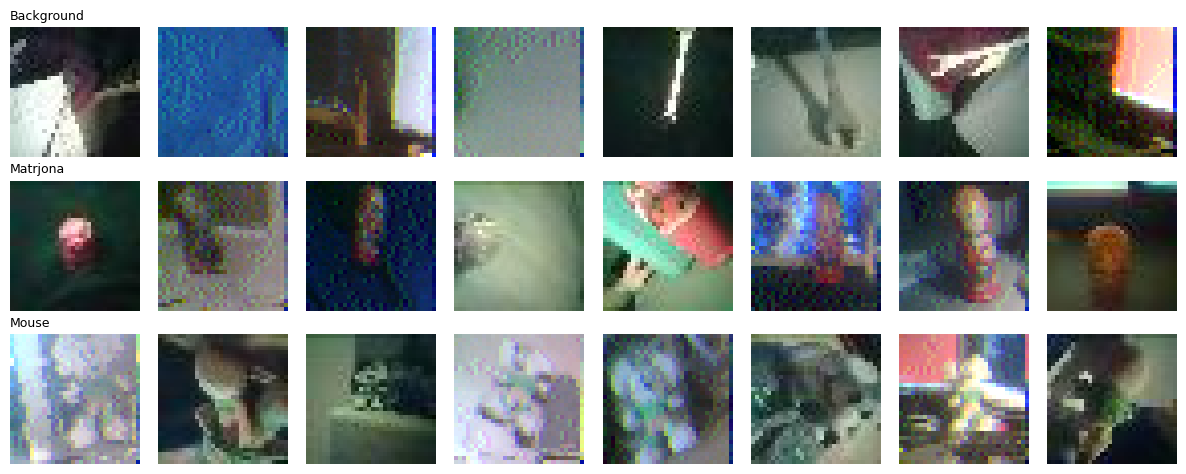

In [3]:
EXTS = (".png", ".jpg", ".jpeg", ".bmp")

# Получаем список классов из папки Train (порядок должен быть одинаковым во всех папках)
LABELS = sorted(d for d in os.listdir(TRAIN_DATASET_PATH) if os.path.isdir(os.path.join(TRAIN_DATASET_PATH, d)))
NUM_of_LABELS = len(LABELS)
print("Классы:", LABELS, "::", NUM_of_LABELS)

def load_dataset_from_folder(folder_path):
    images, labels, paths = [], [], []
    resized = 0
    for class_idx, label in enumerate(LABELS):
        class_folder = os.path.join(folder_path, label)
        if not os.path.exists(class_folder):
            continue
        for fn in sorted(os.listdir(class_folder)):
            if not fn.lower().endswith(EXTS):
                continue
            img = Image.open(os.path.join(class_folder, fn)).convert("RGB")
            if img.size != (IMAGE_WIDTH, IMAGE_HEIGHT):
                img = img.resize((IMAGE_WIDTH, IMAGE_HEIGHT), Image.NEAREST)
                resized += 1
            images.append(np.asarray(img, dtype=np.uint8))
            labels.append(class_idx)
            paths.append(os.path.join(label, fn))
    
    X_set = np.stack(images) if images else np.zeros((0, IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS), dtype=np.uint8)
    Y_set = np.asarray(labels, dtype=np.int64)
    return X_set, Y_set, paths, resized

# Загружаем выборки
x_train, y_train, train_paths, train_resized = load_dataset_from_folder(TRAIN_DATASET_PATH)
x_val, y_val, val_paths, val_resized = load_dataset_from_folder(VAL_DATASET_PATH)
x_test, y_test, test_paths, test_resized = load_dataset_from_folder(TEST_DATASET_PATH)

print(f"\nЗагружено изображений:")
print(f"  Train: {len(x_train)} (изменено размеров: {train_resized})")
print(f"  Val:   {len(x_val)} (изменено размеров: {val_resized})")
print(f"  Test:  {len(x_test)} (изменено размеров: {test_resized})")

print(f"\n{'класс':12s} {'train':>6s} {'val':>6s} {'test':>6s}")
for i, name in enumerate(LABELS):
    print(f"{name:12s} {(y_train==i).sum():6d} {(y_val==i).sum():6d} {(y_test==i).sum():6d}")
print(f"{'ИТОГО':12s} {len(y_train):6d} {len(y_val):6d} {len(y_test):6d}")

# Несколько примеров каждого класса из train-выборки
fig, ax = plt.subplots(NUM_of_LABELS, 8, figsize=(12, 1.6 * NUM_of_LABELS))
ax = np.atleast_2d(ax)
rng = np.random.default_rng(SEED)
for r, name in enumerate(LABELS):
    class_indices = np.where(y_train == r)[0]
    if len(class_indices) > 0:
        idx = rng.choice(class_indices, size=8, replace=len(class_indices) < 8)
        for c, k in enumerate(idx):
            ax[r, c].imshow(x_train[k]); ax[r, c].axis("off")
    ax[r, 0].set_title(name, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

# Аугментация

**Аугментация** (от лат. *augmentatio* — «увеличение») — это искусственное расширение обучающей выборки за счёт применения к каждому примеру случайных, но семантически допустимых преобразований. Формально модель видит гораздо больше «разных» входов, чем лежит на диске, но все они остаются правдоподобными представителями того же класса. Практически аугментация решает три задачи сразу:

1. **Борьба с переобучением.** Особенно на маленьких датасетах (а embedded-CV датасеты почти всегда маленькие: собрать десятки тысяч кадров с конкретной платы дорого) модель склонна запоминать конкретные кадры, а не учить признаки. Аугментация делает «запоминание» бесполезным: один и тот же объект каждый раз выглядит иначе.
2. **Инвариантность к реальной изменчивости.** Между двумя кадрами с одной и той же камеры меняются освещение, экспозиция, небольшой сдвиг и поворот, шум сенсора, иногда — частичное перекрытие объекта. Модель должна не замечать этих вариаций, потому что для неё они не несут информации о классе.
3. **Согласование train и deploy.** Самое важное для этой задачи: аугментации должны имитировать **именно тот** диапазон искажений, который встретится на устройстве, — и ничего сверх него. Слишком агрессивная или «не та» аугментация (например, сильные цветовые сдвиги, которых физически не бывает у этой камеры) не помогает, а вредит: модель учится инвариантности к тому, чего в реальности не будет, и тратит на это ёмкость.

## Как устроен пайплайн

Аугментация разбита на **факторы вариативности**, каждый из которых моделирует независимый источник изменчивости в реальном мире:

* **Геометрия** — поворот, масштаб, сдвиг, отражения. Собираются в **одно аффинное преобразование** и применяются за один проход с одной билинейной интерполяцией (а не четырьмя отдельными), чтобы не накапливать размытие и не платить четырежды за `ImageProjectiveTransform`. Это самый сильный и самый дешёвый вид аугментации для изображений.
* **Фотометрия** — яркость, контраст, гамма, насыщенность, небольшой дисбаланс каналов (имитация баланса белого камеры), шум сенсора, лёгкое размытие. Моделирует разницу между камерами, освещением и условиями съёмки; для TFLM-модели, которая окажется на дешёвом сенсоре, это критично.
* **Random erasing** — закрывает случайный прямоугольник случайным цветом. Учит не опираться на единственный локальный признак (например, только на «ушко» или «ручку» объекта) и имитирует частичное перекрытие в реальной сцене.
* **Mixup** (опционально) — линейно смешивает пары примеров и их метки. Даёт soft-label регуляризацию и заметно улучшает обобщение на маленьких датасетах; включается отдельно, потому что меняет формат таргетов.
* **Округление до сетки `k/255`** в конце — все значения после интерполяции, гаммы и шума «уплывают» в произвольные float. Округление возвращает их ровно на ту решётку, на которой живёт реальный 8-битный кадр и на которой откалиброван int8-вход квантованной модели (`scale = 1/255, zero_point = 0`). Без этого шага train-time распределение входов чуть-чуть расходится с deploy-time, и квантованная модель теряет точность относительно float-эталона.

In [4]:
# Высота и ширина изображения в float.
H_, W_ = float(IMAGE_HEIGHT), float(IMAGE_WIDTH)

def _u(shape, lo, hi):
    return tf.random.uniform(shape, lo, hi, dtype=tf.float32)

# Геометрические искажения одним проективным преобразованием.
def random_affine(x, s):
    # Поворот + масштаб + сдвиг + отражения одним проективным преобразованием. x: float32 [B,H,W,3], 0..1.
    B = tf.shape(x)[0]
    rot = _u([B], -1.0, 1.0) * ROT_DEG * min(s, 1.0) * (math.pi / 180.0)
    z = math.log(1.0 + 0.25 * s)
    inv_zoom = tf.exp(-_u([B], -z, z))                       # масштаб 1/(1+0.25s) ... (1+0.25s)
    tx = _u([B], -0.12 * s, 0.12 * s) * W_
    ty = _u([B], -0.12 * s, 0.12 * s) * H_
    fx = tf.where(_u([B], 0, 1) < 0.5, -1.0, 1.0) if FLIP_H else tf.ones([B])
    fy = tf.where(_u([B], 0, 1) < 0.5, -1.0, 1.0) if FLIP_V else tf.ones([B])

    c, sn = tf.cos(rot), tf.sin(rot)
    m00, m01 = c * fx * inv_zoom, -sn * fy * inv_zoom
    m10, m11 = sn * fx * inv_zoom, c * fy * inv_zoom
    cx, cy = (W_ - 1.0) / 2.0, (H_ - 1.0) / 2.0
    a2 = cx - (m00 * cx + m01 * cy) + tx
    b2 = cy - (m10 * cx + m11 * cy) + ty
    zeros = tf.zeros([B])
    transforms = tf.stack([m00, m01, a2, m10, m11, b2, zeros, zeros], axis=1)
    return tf.raw_ops.ImageProjectiveTransformV3(
        images=x, transforms=transforms,
        output_shape=tf.constant([IMAGE_HEIGHT, IMAGE_WIDTH], dtype=tf.int32),
        fill_value=0.0, interpolation="BILINEAR", fill_mode="NEAREST")


_BLUR_K = np.array([1, 2, 1], dtype=np.float32)
_BLUR_K = np.outer(_BLUR_K, _BLUR_K) / 16.0
_BLUR_K = tf.constant(np.tile(_BLUR_K[:, :, None, None], (1, 1, CHANNELS, 1)))

# Искажения цвета/яркости, имитирующие разное освещение и разные камеры.
def photometric(x, s):
    # Яркость / баланс белого / гамма / контраст / насыщенность / шум / размытие. x: float32 [B,H,W,3], 0..1.
    B = tf.shape(x)[0]
    bshape = [B, 1, 1, 1]
    x = x * _u(bshape, 1.0 - 0.35 * s, 1.0 + 0.35 * s)                     # общая яркость (усиление)
    x = x * _u([B, 1, 1, CHANNELS], 1.0 - 0.10 * s, 1.0 + 0.10 * s)       # баланс белого
    g = _u(bshape, -0.30 * s, 0.30 * s)
    x = tf.pow(tf.clip_by_value(x, 1e-4, 1.0), tf.exp(g))                  # гамма
    mean = tf.reduce_mean(x, axis=[1, 2, 3], keepdims=True)
    x = (x - mean) * _u(bshape, 1.0 - 0.30 * s, 1.0 + 0.30 * s) + mean     # контраст
    gray = tf.reduce_sum(x * tf.constant([0.299, 0.587, 0.114]), axis=-1, keepdims=True)
    x = gray + (x - gray) * _u(bshape, 1.0 - 0.40 * s, 1.0 + 0.40 * s)     # насыщенность
    x = x + _u(bshape, -0.08 * s, 0.08 * s)                                # смещение яркости
    x = tf.clip_by_value(x, 0.0, 1.0)
    # лёгкое размытие у части кадров
    xp = tf.pad(x, [[0, 0], [1, 1], [1, 1], [0, 0]], mode="REFLECT")
    blurred = tf.nn.depthwise_conv2d(xp, _BLUR_K, strides=[1, 1, 1, 1], padding="VALID")
    x = tf.where(_u(bshape, 0, 1) < 0.20 * min(s, 1.5), blurred, x)
    # шум сенсора
    sigma = _u(bshape, 0.0, 0.04 * s)
    x = x + tf.random.normal(tf.shape(x)) * sigma
    return tf.clip_by_value(x, 0.0, 1.0)


# Закрашивает случайный прямоугольник случайным цветом (вероятность 0.25*s).
def random_erasing(x, s):
    B = tf.shape(x)[0]
    area = _u([B], 0.04, 0.20) * H_ * W_
    ratio = tf.exp(_u([B], math.log(0.4), math.log(2.5)))
    h = tf.minimum(tf.sqrt(area * ratio), H_)
    w = tf.minimum(tf.sqrt(area / ratio), W_)
    y0 = _u([B], 0, 1) * (H_ - h)
    x0 = _u([B], 0, 1) * (W_ - w)
    ys = tf.range(IMAGE_HEIGHT, dtype=tf.float32)[None, :, None]
    xs = tf.range(IMAGE_WIDTH, dtype=tf.float32)[None, None, :]
    m = ((ys >= y0[:, None, None]) & (ys < (y0 + h)[:, None, None]) &
         (xs >= x0[:, None, None]) & (xs < (x0 + w)[:, None, None]))
    m = m & (_u([B], 0, 1) < 0.25 * min(s, 2.0))[:, None, None]
    fill = _u([B, 1, 1, CHANNELS], 0.0, 1.0)
    return tf.where(m[..., None], fill, x)


# Смешивание батча, линейно смешивает пары примеров и их метки.
def mixup(x, y, alpha):
    B = tf.shape(x)[0]
    g1 = tf.random.gamma([B], alpha)
    g2 = tf.random.gamma([B], alpha)
    lam = g1 / (g1 + g2 + 1e-8)
    idx = tf.random.shuffle(tf.range(B))
    lx = lam[:, None, None, None]
    ly = lam[:, None]
    return lx * x + (1.0 - lx) * tf.gather(x, idx), ly * y + (1.0 - ly) * tf.gather(y, idx)


# Полная цепочка аугментации для батча uint8 -> float32 0..1 (на сетке k/255).
def augment_batch(x_u8):
    s = AUG_STRENGTH
    x = tf.cast(x_u8, tf.float32) / 255.0
    if s > 0:
        x = random_affine(x, s)
        x = photometric(x, s)
        x = random_erasing(x, s)
    return tf.round(x * 255.0) / 255.0

# Визуализация аугментированных данных

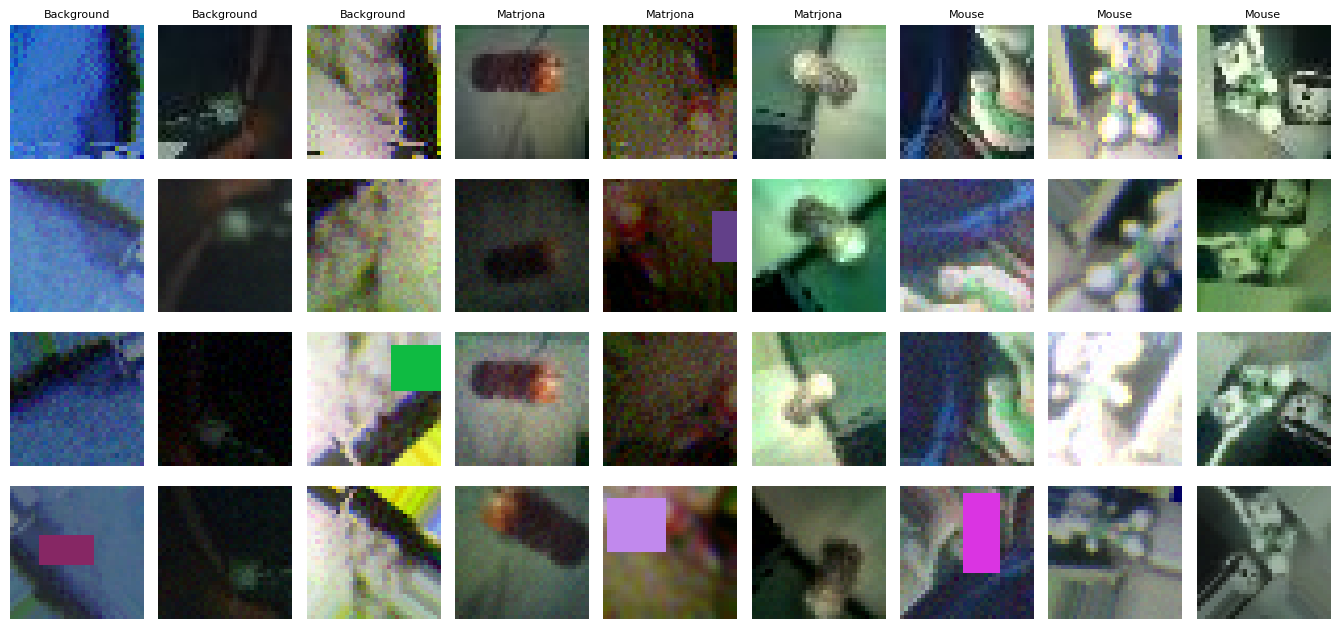

In [5]:
# Визуальная проверка: верхняя строка - исходные кадры, ниже - три случайные аугментации каждого.
n_show = 9
sel = np.concatenate([rng.choice(np.where(y_train == c)[0], size=n_show // NUM_of_LABELS, replace=False)
                      for c in range(NUM_of_LABELS)])[:n_show]
base = x_train[sel]
fig, ax = plt.subplots(4, n_show, figsize=(1.5 * n_show, 6.5))
for j in range(n_show):
    ax[0, j].imshow(base[j]); ax[0, j].axis("off")
    ax[0, j].set_title(LABELS[y_train[sel][j]], fontsize=8)
for r in range(1, 4):
    aug = augment_batch(tf.constant(base)).numpy()
    for j in range(n_show):
        ax[r, j].imshow(aug[j]); ax[r, j].axis("off")
plt.tight_layout(); plt.show()

# Конвейер данных `tf.data`
Конвейер данных решает задачи по загрузке, аугментации и передаче данных на вход обучаемой сети.

In [6]:
AUTOTUNE = tf.data.AUTOTUNE

# Собирает тренировочный датасет.
def make_train_ds(x_u8, y_int):
    ds = tf.data.Dataset.from_tensor_slices((x_u8, y_int))
    ds = ds.shuffle(len(x_u8), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)

    # Внутренняя функция, применяемая к каждому батчу. Делает три вещи:
    # • вся цепочка аугментации.
    # • метки из int в one-hot вектор.
    # • если включён, линейно смешивает пары (x, y).
    def _map(xb, yb):
        x = augment_batch(xb)
        y = tf.one_hot(yb, NUM_of_LABELS)
        if MIXUP_ALPHA > 0:
            x, y = mixup(x, y, MIXUP_ALPHA)
        return x, y

    return ds.map(_map, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# Собирает валидационный/тестовый датасет.
def make_eval_ds(x_u8, y_int):
    ds = tf.data.Dataset.from_tensor_slices((x_u8, y_int)).batch(128)
    ds = ds.map(lambda xb, yb: (tf.cast(xb, tf.float32) / 255.0, tf.one_hot(yb, NUM_of_LABELS)),
                num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)


train_ds = make_train_ds(x_train, y_train)
val_ds = make_eval_ds(x_val, y_val)
test_ds = make_eval_ds(x_test, y_test)

# Веса классов нужны только при заметном дисбалансе.
counts = np.bincount(y_train, minlength=NUM_of_LABELS)
if counts.max() / max(1, counts.min()) > 1.25:
    CLASS_WEIGHT = {i: float(len(y_train) / (NUM_of_LABELS * c)) for i, c in enumerate(counts)}
else:
    CLASS_WEIGHT = None
print("Распределение train:", dict(zip(LABELS, counts.tolist())), "| class_weight:", CLASS_WEIGHT)

Распределение train: {'Background': 645, 'Matrjona': 638, 'Mouse': 623} | class_weight: None


# СВЁРТОЧНЫЕ НЕЙРОННЫЕ СЕТИ
**Свёрточная нейронная сеть — это инструмент в компьютерном зрении, который использует математическую операцию, называемую свёрткой, для извлечения признаков из изображений.**

* **Свёртка выполняется путём перемножения двух матриц и получения третьей, меньшей матрицы.**
* **Сеть принимает входное изображение и использует фильтр (или ядро) для создания карты признаков, описывающей изображение.**
* **В операции свёртки фильтр (обычно матрица 2x2 или 3x3) скользит по матрице изображения. Соответствующие числа в обеих матрицах перемножаются и складываются, образуя одно число, описывающее данный участок изображения. Этот процесс повторяется для всего изображения. Принцип работы показан на следующей иллюстрации.**

<img src="images\cnn.jpg"
     width="100%"
     style="display:block; margin-left:auto; margin-right:auto;">
     
<img src="images\conv.gif"
     width="70%"
     style="display:block; margin-left:auto; margin-right:auto;">


Так как на микроконтроллере время инференса  напрямую определяется числом операций **MAC** (Multiply-Accumulate, «умножение-накопление»). Каждый выходной пиксель свёртки — это `k·k·C_in` умножений с накоплением в одно число. Суммарно:

$$\text{MAC}_{\text{Conv2D}} = H_{out} \cdot W_{out} \cdot C_{out} \cdot C_{in} \cdot k^2$$

Именно эта величина, определяет, сколько миллисекунд модель будет обрабатывать изображение. Это главный показатель при выборе архитектуры, который диктует ряд принципов в архитектуре модели:

* Маленькое входное разрешение изображения 32х32.

* Маленькое число каналов на картах признаков с большим разрешением.

* Depthwise-separable блоки вместо полных `Conv 3×3`

* `BatchNorm` стабилизирует обучение (нормализует активации по батчу), а на инференсе сливается со свёрткой в один слой — в графе TFLM её вообще нет, она не добавляет ни MAC, ни параметров.

*  `ReLU6` вместо обычного `ReLU`, так как он хорошо квантуется в int8 диапазон [0, 6] и отображается на 8-битную сетку без потери диапазона, тогда как у `ReLU` верхняя граница не ограничена и требует отдельной оценки `max` при калибровке.

*  GlobalAveragePooling вместо Flatten + Dense после последней свёрточной стадии, что даёт в 16 раз меньше параметров, а точность почти не страдает.

*  Вход модели float32 0..1 хорошо квантуется в int8 диапозон от -128 до 127.

*  Используются только поддерживаемые операции: Conv2D, DepthwiseConv2D, MaxPool2D, AveragePool2D, Reshape, FullyConnected, Softmax. 

In [ ]:
# Блок реализует обычную (полную) свёртку: каждый выходной канал смотрит на все входные каналы. 
# Один фильтр = тензор kernel×kernel×C_in, и таких фильтров filters.
def conv_bn_relu(x, filters, kernel, name):
    x = tf.keras.layers.Conv2D(filters, kernel, padding="same", use_bias=False, name=name + "_conv")(x)
    x = tf.keras.layers.BatchNormalization(momentum=0.9, name=name + "_bn")(x)
    return tf.keras.layers.ReLU(max_value=6.0, name=name + "_relu6")(x)

# Блок реализует по-канальную свёртку: каждый входной канал сворачивается своим собственным фильтром независимо, 
# каналы не смешиваются. Один фильтр = kernel×kernel×1, применяется к одному каналу.
def sep_block(x, filters, name):
    if BLOCK_TYPE == "conv":
        return conv_bn_relu(x, filters, 3, name)
    x = tf.keras.layers.DepthwiseConv2D(3, padding="same", use_bias=False, name=name + "_dw")(x)
    x = tf.keras.layers.BatchNormalization(momentum=0.9, name=name + "_dw_bn")(x)
    x = tf.keras.layers.ReLU(max_value=6.0, name=name + "_dw_relu6")(x)
    return conv_bn_relu(x, filters, 1, name + "_pw")

# Функция собирает модель по пресету ширины сети из конфигурации в начале проекта.
def build_model(preset):
    cfg = PRESETS[preset]
    inp = tf.keras.Input(shape=(IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS), name="input")
    x = conv_bn_relu(inp, cfg["stem"], 3, "stem")                      # 32x32
    x = tf.keras.layers.MaxPool2D(2, name="pool0")(x)                  # 16x16
    for si, filters in enumerate(cfg["stages"]):
        for bi in range(cfg["blocks_per_stage"]):
            x = sep_block(x, filters, f"s{si}b{bi}")
        if si < len(cfg["stages"]) - 1:
            x = tf.keras.layers.MaxPool2D(2, name=f"pool{si + 1}")(x)  # 8x8, 4x4
    # Глобальное усреднение через AveragePool2D на всю карту (в TFLM это AveragePool2D + Reshape, без операции Mean).
    x = tf.keras.layers.AveragePooling2D(pool_size=x.shape[1:3], name="gap")(x)
    x = tf.keras.layers.Flatten(name="flatten")(x)
    x = tf.keras.layers.Dropout(0.2, name="drop")(x)
    out = tf.keras.layers.Dense(NUM_of_LABELS, activation="softmax", name="output")(x)
    return tf.keras.Model(inp, out, name=f"cnn_{preset}")

# Расчёт количества MAC операций для модели
def count_macs(model):
    macs = 0
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.DepthwiseConv2D):
            _, oh, ow, c = layer.output_shape
            k = layer.kernel_size[0] * layer.kernel_size[1]
            macs += oh * ow * c * k * layer.depth_multiplier
        elif isinstance(layer, tf.keras.layers.Conv2D):
            _, oh, ow, cout = layer.output_shape
            cin = layer.input_shape[-1]
            macs += oh * ow * cout * cin * layer.kernel_size[0] * layer.kernel_size[1]
        elif isinstance(layer, tf.keras.layers.Dense):
            macs += layer.input_shape[-1] * layer.units
    return macs


print(f"{'preset':8s} {'params':>9s} {'MAC':>11s}")
for name in PRESETS:
    m = build_model(name)
    macs = count_macs(m)
    print(f"{name:8s} {m.count_params():9d} {macs:11,d}")

build_model(SELECTED_PRESET).summary()

preset      params         MAC
small         8475     601,632
medium       13987     900,480
big          83139   3,608,640
Model: "cnn_medium"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input (InputLayer)          [(None, 32, 32, 3)]       0         
                                                                 
 stem_conv (Conv2D)          (None, 32, 32, 16)        432       
                                                                 
 stem_bn (BatchNormalizatio  (None, 32, 32, 16)        64        
 n)                                                              
                                                                 
 stem_relu6 (ReLU)           (None, 32, 32, 16)        0         
                                                                 
 pool0 (MaxPooling2D)        (None, 16, 16, 16)        0         
                                                                

# Обучение
* **AdamW** (развязанный weight decay, без decay для BatchNorm и bias).
* **Warmup + cosine decay** скорости обучения вместо `ReduceLROnPlateau`.
* **Label smoothing** против переуверенности (и против нулевых вероятностей на выходе, которые плохо квантуются).
* Сохраняется **лучшая** по `val_loss` эпоха, а не последняя.

In [8]:
# Подкласс LearningRateSchedule — вызываемый объект, который по номеру шага оптимизатора возвращает текущий learning rate.
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, peak, total_steps, warmup_steps, floor=1e-5):
        super().__init__()
        self.peak, self.total, self.warmup, self.floor = peak, float(total_steps), float(warmup_steps), floor

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = self.peak * (step + 1.0) / max(1.0, self.warmup)
        prog = tf.clip_by_value((step - self.warmup) / max(1.0, self.total - self.warmup), 0.0, 1.0)
        cosine = self.floor + (self.peak - self.floor) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        return tf.where(step < self.warmup, warm, cosine)

    def get_config(self):
        return dict(peak=self.peak, total_steps=self.total, warmup_steps=self.warmup, floor=self.floor)

# Колбэк для лога
class PrintEvery(tf.keras.callbacks.Callback):
    def __init__(self, every, tag):
        super().__init__(); self.every, self.tag = every, tag

    def on_epoch_end(self, epoch, logs=None):
        if epoch == 0 or (epoch + 1) % self.every == 0:
            print(f"[{self.tag}] epoch {epoch + 1:3d} | loss {logs['loss']:.3f} acc {logs['accuracy']:.3f} | "
                  f"val_loss {logs['val_loss']:.3f} val_acc {logs['val_accuracy']:.3f}")


# Сборка оптимизатора.
def make_optimizer(steps_per_epoch, epochs):
    sched = WarmupCosine(PEAK_LR, steps_per_epoch * epochs, steps_per_epoch * WARMUP_EPOCHS)
    opt = tf.keras.optimizers.AdamW(learning_rate=sched, weight_decay=WEIGHT_DECAY)
    opt.exclude_from_weight_decay(var_names=["gamma", "beta", "bias"])
    return opt

# Сборка функции потерь.
def make_loss():
    return tf.keras.losses.CategoricalCrossentropy(label_smoothing=LABEL_SMOOTHING)

# Полный цикл обучения одного пресета.
def train_preset(preset):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(preset)
    steps = max(1, len(x_train) // BATCH_SIZE)
    model.compile(optimizer=make_optimizer(steps, EPOCHS), loss=make_loss(), metrics=["accuracy"])
    ckpt_path = os.path.join(OUT_DIR, f"best_{preset}.weights.h5")
    callbacks = [
        tf.keras.callbacks.ModelCheckpoint(ckpt_path, monitor="val_loss", mode="min",
                                           save_best_only=True, save_weights_only=True),
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=EARLY_STOP_PATIENCE),
        PrintEvery(10, preset),
    ]
    t0 = time.time()
    history = model.fit(train_ds, epochs=EPOCHS, validation_data=val_ds,
                        class_weight=CLASS_WEIGHT, callbacks=callbacks, verbose=0)
    model.load_weights(ckpt_path)                       # лучшая эпоха
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    print(f"[{preset}] готово за {time.time() - t0:.0f} с | лучшая val_loss {val_loss:.3f}, val_acc {val_acc:.3f}")
    return model, history, dict(val_loss=val_loss, val_acc=val_acc)


models, histories, results = {}, {}, {}
for name in PRESETS_TO_TRAIN:
    models[name], histories[name], results[name] = train_preset(name)

[small] epoch   1 | loss 1.116 acc 0.391 | val_loss 1.038 val_acc 0.500
[small] epoch  10 | loss 0.796 acc 0.689 | val_loss 0.674 val_acc 0.817
[small] epoch  20 | loss 0.707 acc 0.765 | val_loss 0.598 val_acc 0.817
[small] epoch  30 | loss 0.691 acc 0.771 | val_loss 0.567 val_acc 0.853
[small] epoch  40 | loss 0.659 acc 0.789 | val_loss 0.537 val_acc 0.880
[small] epoch  50 | loss 0.647 acc 0.789 | val_loss 0.561 val_acc 0.867
[small] epoch  60 | loss 0.625 acc 0.807 | val_loss 0.577 val_acc 0.847
[small] epoch  70 | loss 0.609 acc 0.819 | val_loss 0.496 val_acc 0.897
[small] epoch  80 | loss 0.618 acc 0.819 | val_loss 0.504 val_acc 0.903
[small] epoch  90 | loss 0.606 acc 0.819 | val_loss 0.511 val_acc 0.897
[small] epoch 100 | loss 0.591 acc 0.837 | val_loss 0.494 val_acc 0.900
[small] epoch 110 | loss 0.585 acc 0.840 | val_loss 0.483 val_acc 0.890
[small] epoch 120 | loss 0.579 acc 0.841 | val_loss 0.526 val_acc 0.863
[small] epoch 130 | loss 0.593 acc 0.827 | val_loss 0.472 val_ac

# Сравнение пресетов
Выбор модели делается по val-метрикам, соотношению точности и стоимости (MAC).

preset      params         MAC  val_acc  val_loss
small         8475     601,632    0.930     0.435
medium       13987     900,480    0.943     0.441
big          83139   3,608,640    0.953     0.383


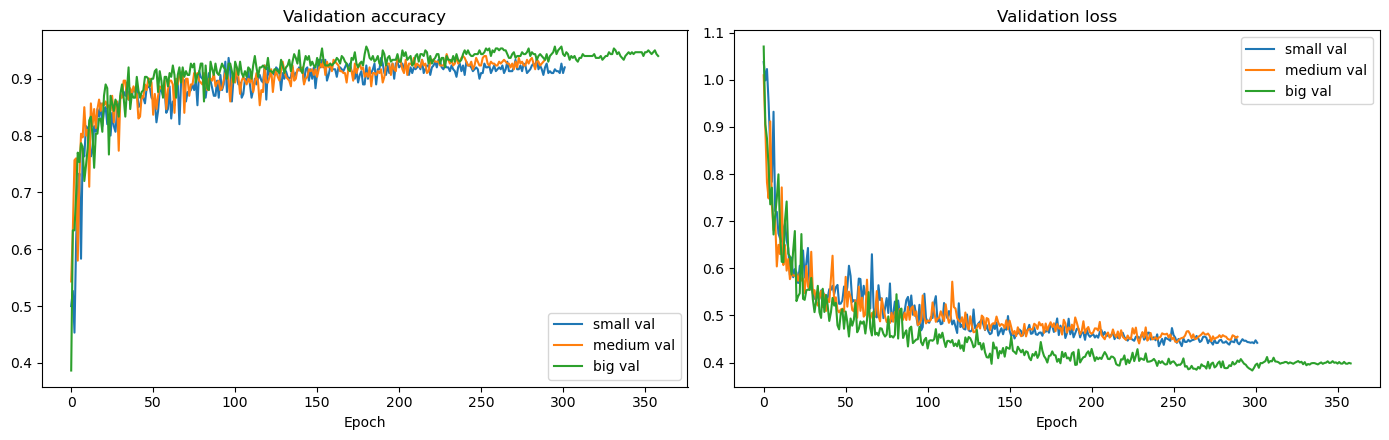

In [9]:
print(f"{'preset':8s} {'params':>9s} {'MAC':>11s} {'val_acc':>8s} {'val_loss':>9s}")
for name in PRESETS_TO_TRAIN:
    m = models[name]
    macs = count_macs(m)
    r = results[name]
    print(f"{name:8s} {m.count_params():9d} {macs:11,d} {r['val_acc']:8.3f} {r['val_loss']:9.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for name in PRESETS_TO_TRAIN:
    h = histories[name].history
    ax[0].plot(h["val_accuracy"], label=f"{name} val")
    ax[1].plot(h["val_loss"], label=f"{name} val")
ax[0].set_title("Validation accuracy"); ax[1].set_title("Validation loss")
for a in ax:
    a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

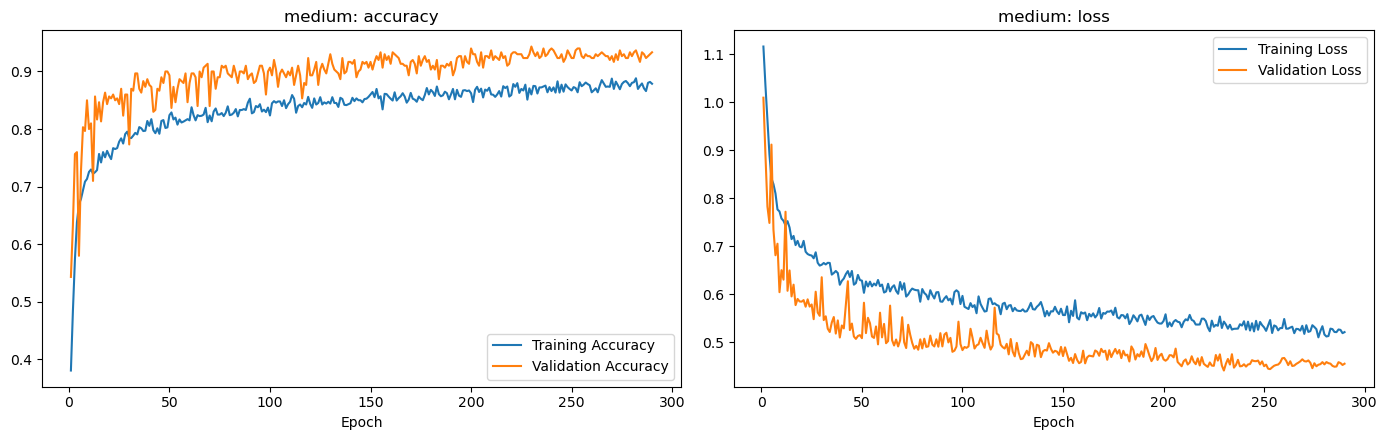

In [10]:
# Выбранная модель: кривые обучения.
assert SELECTED_PRESET in models, "SELECTED_PRESET должен входить в PRESETS_TO_TRAIN"
model = models[SELECTED_PRESET]
h = histories[SELECTED_PRESET].history
ep = range(1, len(h["loss"]) + 1)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(ep, h["accuracy"], label="Training Accuracy"); ax[0].plot(ep, h["val_accuracy"], label="Validation Accuracy")
ax[0].set_title(f"{SELECTED_PRESET}: accuracy"); ax[0].legend(); ax[0].set_xlabel("Epoch")
ax[1].plot(ep, h["loss"], label="Training Loss"); ax[1].plot(ep, h["val_loss"], label="Validation Loss")
ax[1].set_title(f"{SELECTED_PRESET}: loss"); ax[1].legend(); ax[1].set_xlabel("Epoch")
plt.tight_layout(); plt.show()

# Финальная оценка float-модели на TEST

Float-модель (medium) на TEST: accuracy = 92.33 %  (n = 300)
              precision    recall  f1-score   support

  Background      0.890     0.890     0.890       100
    Matrjona      0.941     0.960     0.950       100
       Mouse      0.939     0.920     0.929       100

    accuracy                          0.923       300
   macro avg      0.923     0.923     0.923       300
weighted avg      0.923     0.923     0.923       300



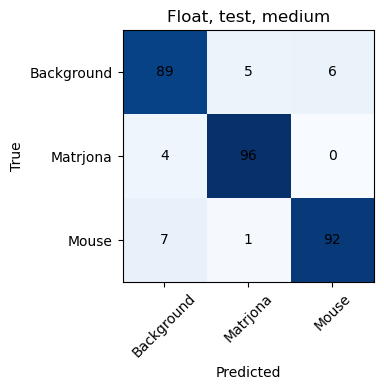

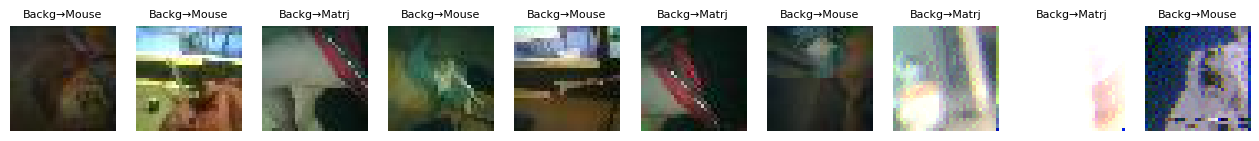

C:\Users\STEPANJUK\.conda\envs\STEP1\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [11]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Float-модель ({SELECTED_PRESET}) на TEST: accuracy = {test_acc * 100:.2f} %  (n = {len(y_test)})")

probs_float = model.predict(test_ds, verbose=0)
pred_float = probs_float.argmax(axis=1)
print(classification_report(y_test, pred_float, target_names=LABELS, digits=3))


def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=range(NUM_of_LABELS))
    fig, a = plt.subplots(figsize=(4.5, 4))
    a.imshow(cm, cmap="Blues")
    a.set_xticks(range(NUM_of_LABELS)); a.set_xticklabels(LABELS, rotation=45)
    a.set_yticks(range(NUM_of_LABELS)); a.set_yticklabels(LABELS)
    for i in range(NUM_of_LABELS):
        for j in range(NUM_of_LABELS):
            a.text(j, i, cm[i, j], ha="center", va="center", color="black")
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(title)
    plt.tight_layout(); plt.show()


plot_confusion(y_test, pred_float, f"Float, test, {SELECTED_PRESET}")

# Ошибочные примеры.
wrong = np.where(pred_float != y_test)[0][:10]
if len(wrong):
    fig, ax = plt.subplots(1, len(wrong), figsize=(1.6 * len(wrong), 2.2))
    ax = np.atleast_1d(ax)
    for a, k in zip(ax, wrong):
        a.imshow(x_test[k]); a.axis("off")
        a.set_title(f"{LABELS[y_test[k]][:5]}→{LABELS[pred_float[k]][:5]}", fontsize=8)
    plt.show()

model.save(os.path.join(OUT_DIR, f"model_{SELECTED_PRESET}.h5"))

# Квантование в INT8
**Post-training quantization (PTQ)** с полным целочисленным выводом.

In [12]:
def build_representative(n, seed=SEED):
    rng_ = np.random.default_rng(seed)
    per_class = max(1, n // NUM_of_LABELS)
    idx = np.concatenate([rng_.choice(np.where(y_train == c)[0], size=per_class,
                                      replace=len(np.where(y_train == c)[0]) < per_class)
                          for c in range(NUM_of_LABELS)])
    clean = x_train[idx].astype(np.float32) / 255.0
    half = len(clean) // 2
    varied = clean.copy()
    varied[:half] = photometric(tf.constant(clean[:half]), 0.7).numpy()       # разное освещение / шум
    samples = np.concatenate([varied,
                              np.zeros((1, IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS), np.float32),   # чёрный кадр
                              np.ones((1, IMAGE_HEIGHT, IMAGE_WIDTH, CHANNELS), np.float32)])   # белый кадр
    return samples


rep_samples = build_representative(CALIB_SAMPLES)
print("Репрезентативная выборка:", rep_samples.shape)


def make_representative_gen(samples):
    def gen():
        for s in samples:
            yield [s[None, ...]]
    return gen


def convert_int8(keras_model, samples):
    conv = tf.lite.TFLiteConverter.from_keras_model(keras_model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    conv.representative_dataset = make_representative_gen(samples)
    conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    conv.inference_input_type = tf.int8
    conv.inference_output_type = tf.int8
    return conv.convert()


tflite_ptq = convert_int8(model, rep_samples)
print(f"TFLite INT8: {len(tflite_ptq)} байт ({len(tflite_ptq) / 1024:.1f} КБ)")

Репрезентативная выборка: (1901, 32, 32, 3)
INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp81qgev_c\assets


INFO:tensorflow:Assets written to: C:\Users\STEPAN~1\AppData\Local\Temp\tmp81qgev_c\assets
C:\Users\STEPANJUK\.conda\envs\STEP1\lib\site-packages\tensorflow\lite\python\convert.py:887: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


TFLite INT8: 29208 байт (28.5 КБ)


In [13]:
def load_interpreter(tflite_bytes, reference=True):
    kwargs = {}
    if reference:
        kwargs["experimental_op_resolver_type"] = tf.lite.experimental.OpResolverType.BUILTIN_REF
    it = tf.lite.Interpreter(model_content=tflite_bytes, **kwargs)
    it.allocate_tensors()
    return it


def io_quant(interp):
    i = interp.get_input_details()[0]
    o = interp.get_output_details()[0]
    return i, o


def run_int8(tflite_bytes, x_u8):
    # Прогон INT8-модели ровно так, как это делает прошивка: вход int8 = пиксель - 128. Возвращает сырые int8-выходы.
    it = load_interpreter(tflite_bytes)
    i, o = io_quant(it)
    q_in = (x_u8.astype(np.int16) - 128).astype(np.int8)
    out = np.empty((len(x_u8), NUM_of_LABELS), dtype=np.int8)
    for k in range(len(x_u8)):
        it.set_tensor(i["index"], q_in[k:k + 1])
        it.invoke()
        out[k] = it.get_tensor(o["index"])[0]
    return out


def check_io_quantization(tflite_bytes):
    it = load_interpreter(tflite_bytes)
    i, o = io_quant(it)
    in_scale, in_zp = i["quantization"]
    out_scale, out_zp = o["quantization"]
    print(f"Вход : dtype={i['dtype'].__name__}, scale={in_scale:.8f} (1/255={1 / 255:.8f}), zero_point={in_zp}")
    print(f"Выход: dtype={o['dtype'].__name__}, scale={out_scale:.8f} (1/256={1 / 256:.8f}), zero_point={out_zp}")
    ok_in = (i["dtype"] == np.int8) and abs(in_scale - 1.0 / 255.0) < 1e-6 and in_zp == -128
    # Эквивалентность формулам прошивки: квантование идеальных значений k/255 даёт k - 128.
    k = np.arange(256)
    q = np.clip(np.round((k / 255.0) / in_scale + in_zp), -128, 127).astype(int)
    ok_formula = np.array_equal(q, k - 128)
    print("Вход эквивалентен 'пиксель - 128' (как в прошивке):", ok_in and ok_formula)
    return ok_in and ok_formula, (out_scale, out_zp)


ok_input, (out_scale, out_zp) = check_io_quantization(tflite_ptq)
assert ok_input, ("Квантование входа отличается от 'пиксель - 128'. Прошивку нужно будет менять (формула в "
                  "tflm_wrapper_classify) либо пересчитать калибровку.")

Вход : dtype=int8, scale=0.00392157 (1/255=0.00392157), zero_point=-128
Выход: dtype=int8, scale=0.00390625 (1/256=0.00390625), zero_point=-128
Вход эквивалентен 'пиксель - 128' (как в прошивке): True


TEST accuracy: float = 92.33 %, INT8 (PTQ) = 92.33 %
Совпадение предсказаний float/INT8: 100.00 %
Макс. отклонение вероятностей: 0.040, среднее: 0.0034
              precision    recall  f1-score   support

  Background      0.890     0.890     0.890       100
    Matrjona      0.941     0.960     0.950       100
       Mouse      0.939     0.920     0.929       100

    accuracy                          0.923       300
   macro avg      0.923     0.923     0.923       300
weighted avg      0.923     0.923     0.923       300



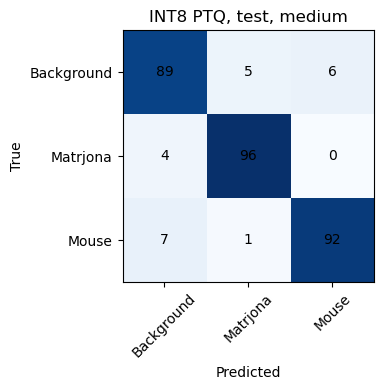

Просадка 0.0 п.п. в пределах нормы. QAT не требуется.


In [14]:
raw_ptq = run_int8(tflite_ptq, x_test)
pred_ptq = raw_ptq.argmax(axis=1)
acc_ptq = float((pred_ptq == y_test).mean())
agree = float((pred_ptq == pred_float).mean())
probs_int8 = (raw_ptq.astype(np.float32) - out_zp) * out_scale

print(f"TEST accuracy: float = {test_acc * 100:.2f} %, INT8 (PTQ) = {acc_ptq * 100:.2f} %")
print(f"Совпадение предсказаний float/INT8: {agree * 100:.2f} %")
print(f"Макс. отклонение вероятностей: {np.abs(probs_int8 - probs_float).max():.3f}, среднее: {np.abs(probs_int8 - probs_float).mean():.4f}")
print(classification_report(y_test, pred_ptq, target_names=LABELS, digits=3))
plot_confusion(y_test, pred_ptq, f"INT8 PTQ, test, {SELECTED_PRESET}")

drop = test_acc - acc_ptq
if drop > MAX_ACC_DROP:
    print(f"Просадка {drop * 100:.1f} п.п. > {MAX_ACC_DROP * 100:.1f} п.п. Включите RUN_QAT = True и перезапустите ячейки ниже.")
else:
    print(f"Просадка {drop * 100:.1f} п.п. в пределах нормы. QAT не требуется.")

FINAL_TFLITE = tflite_ptq
FINAL_NAME = "PTQ"

# Экспорт для Zephyr
Формируются:

1. `export/model.tflite`
2. `export/model.cpp` в формате вашего проекта (`alignas(8) const unsigned char g_model[]` + `g_model_len`)
3. список операций для `MicroMutableOpResolver` (по факту, что лежит в модели)
4. массив меток (порядок должен совпадать с обучением) и оценка размера арены

In [15]:
# 1) .tflite
tflite_path = os.path.join(OUT_DIR, "model.tflite")
with open(tflite_path, "wb") as f:
    f.write(FINAL_TFLITE)

# 2) model.cpp в формате проекта
def tflite_to_cpp(data, path):
    lines = []
    for i in range(0, len(data), 12):
        lines.append("  " + ", ".join(f"0x{b:02x}" for b in data[i:i + 12]))
    body = ",\n".join(lines)
    text = ('#include "model.hpp"\n\n'
            '/* Keep model aligned to 8 bytes to guarantee aligned 64-bit accesses. */\n'
            'alignas(8) const unsigned char g_model[] = {\n' + body + '\n};\n'
            f'const int g_model_len = {len(data)};\n')
    with open(path, "w", newline="\n") as f:
        f.write(text)


tflite_to_cpp(FINAL_TFLITE, os.path.join(OUT_DIR, "model.cpp"))
print(f"model.tflite и model.cpp сохранены в '{OUT_DIR}/', размер модели: {len(FINAL_TFLITE)} байт")

# 3) Операции для резолвера
OP_TO_TFLM = {
    "CONV_2D": "AddConv2D", "DEPTHWISE_CONV_2D": "AddDepthwiseConv2D", "MAX_POOL_2D": "AddMaxPool2D",
    "AVERAGE_POOL_2D": "AddAveragePool2D", "RESHAPE": "AddReshape", "FULLY_CONNECTED": "AddFullyConnected",
    "SOFTMAX": "AddSoftmax", "QUANTIZE": "AddQuantize", "DEQUANTIZE": "AddDequantize", "MEAN": "AddMean",
    "ADD": "AddAdd", "MUL": "AddMul", "PAD": "AddPad", "RELU": "AddRelu", "RELU6": "AddRelu6",
    "LOGISTIC": "AddLogistic", "CONCATENATION": "AddConcatenation",
}
it_ops = load_interpreter(FINAL_TFLITE, reference=True)   # без делегатов, чтобы в списке были только реальные операции
ops = it_ops._get_ops_details()
op_names = sorted({o["op_name"] for o in ops})
unknown = [n for n in op_names if n not in OP_TO_TFLM]
print("\nОперации в модели:", op_names)
if unknown:
    print("ВНИМАНИЕ: нет сопоставления для", unknown, "- добавьте соответствующий AddXxx() вручную.")

print("\n// --- вставьте в tflm_wrapper.cpp ---")
print(f"static tflite::MicroMutableOpResolver<{len(op_names)}> micro_op_resolver;")
for n in op_names:
    if n in OP_TO_TFLM:
        print(f"micro_op_resolver.{OP_TO_TFLM[n]}();")

print("\n// --- массив меток (порядок = обучение) ---")
print("const char *const kCategoryLabels[TFLM_NUM_CLASSES] = {" + ", ".join(f'"{l}"' for l in LABELS) + "};")
print(f"// TFLM_NUM_CLASSES = {NUM_of_LABELS}")

model.tflite и model.cpp сохранены в 'export/', размер модели: 29208 байт

Операции в модели: ['AVERAGE_POOL_2D', 'CONV_2D', 'DEPTHWISE_CONV_2D', 'FULLY_CONNECTED', 'MAX_POOL_2D', 'RESHAPE', 'SOFTMAX']

// --- вставьте в tflm_wrapper.cpp ---
static tflite::MicroMutableOpResolver<7> micro_op_resolver;
micro_op_resolver.AddAveragePool2D();
micro_op_resolver.AddConv2D();
micro_op_resolver.AddDepthwiseConv2D();
micro_op_resolver.AddFullyConnected();
micro_op_resolver.AddMaxPool2D();
micro_op_resolver.AddReshape();
micro_op_resolver.AddSoftmax();

// --- массив меток (порядок = обучение) ---
const char *const kCategoryLabels[TFLM_NUM_CLASSES] = {"Background", "Matrjona", "Mouse"};
// TFLM_NUM_CLASSES = 3


In [16]:
# 4) Оценка размера арены. Активации = вход модели + выходы операций. Для каждой операции считаем сумму её входных
# и выходных активаций; максимум - нижняя оценка пика (реальный планировщик TFLM добавляет накладные расходы).
det = {d["index"]: d for d in it_ops.get_tensor_details()}
act = {it_ops.get_input_details()[0]["index"]}
for o in ops:
    act.update(int(i) for i in o["outputs"])


def nbytes(idx):
    d = det[idx]
    return int(np.prod(d["shape"])) * np.dtype(d["dtype"]).itemsize


peak = 0
for o in ops:
    cur = sum(nbytes(int(i)) for i in set(list(o["inputs"]) + list(o["outputs"])) if int(i) in act)
    peak = max(peak, cur)

recommended = int(math.ceil((peak * 1.3 + 8 * 1024) / 1024.0) * 1024)
total_macs = count_macs(model)
print(f"Пик активаций (нижняя оценка): {peak / 1024:.1f} КБ")
print(f"Рекомендуемый kTensorArenaSize для старта: {recommended // 1024} КБ  "
      f"(реальное значение прошивка печатает в логе: 'arena used')")
print(f"MAC: {total_macs:,d}")


summary = dict(preset=SELECTED_PRESET, quantization=FINAL_NAME, labels=LABELS, params=int(model.count_params()),
               macs=int(total_macs), tflite_bytes=len(FINAL_TFLITE), arena_recommended_bytes=recommended,
               test_acc_float=float(test_acc), test_acc_int8=float(acc_ptq if FINAL_NAME == "PTQ" else acc_qat),
               input_scale=1 / 255, input_zero_point=-128, output_scale=float(out_scale), output_zero_point=int(out_zp))
with open(os.path.join(OUT_DIR, "summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print(json.dumps(summary, ensure_ascii=False, indent=2))

Пик активаций (нижняя оценка): 20.0 КБ
Рекомендуемый kTensorArenaSize для старта: 34 КБ  (реальное значение прошивка печатает в логе: 'arena used')
MAC: 900,480
{
  "preset": "medium",
  "quantization": "PTQ",
  "labels": [
    "Background",
    "Matrjona",
    "Mouse"
  ],
  "params": 13987,
  "macs": 900480,
  "tflite_bytes": 29208,
  "arena_recommended_bytes": 34816,
  "test_acc_float": 0.9233333468437195,
  "test_acc_int8": 0.9233333333333333,
  "input_scale": 0.00392156862745098,
  "input_zero_point": -128,
  "output_scale": 0.00390625,
  "output_zero_point": -128
}


# Учебное пособие:

### TensorFlow:
##### ESP32-CAM 15: TensorFlow LITE классификация изображений
https://www.youtube.com/watch?v=ORJrzHiHIDc&t=660s

https://vkvideo.ru/video63898488_456239464?pl=63898488_-2

##### ESP32 + CatBoost: Decision Trees for Color Classification (GY-31-TCS230)
https://www.youtube.com/watch?v=CmU3OemU6gk

https://vkvideo.ru/video-229753773_456239017

##### ESP32 + KNN: Метод K-ближайших соседей для классификации цветов (GY-31-TCS230)
https://www.youtube.com/watch?v=0kSWgAhEtCI

https://www.youtube.com/watch?v=0kSWgAhEtCI

##### ESP32 + TensorFlow Lite: Линейная модель для классификации цветов (GY-31-TCS230)
https://www.youtube.com/watch?v=DyiEhkdACyw

https://vkvideo.ru/video-229753773_456239019

##### ESP32 + LD2410: Линейная модель для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=ds3CPqLV-MI

https://www.youtube.com/watch?v=ds3CPqLV-MI

##### ESP32 + LD2410: Сверточная нейронная сеть для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=kC0A1RCqdIc

https://vkvideo.ru/video-229753773_456239021

##### ESP32 + LD2410: Рекуррентная нейронная сеть для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=UZd4lkwPL3Q&t=1s

https://vkvideo.ru/video-229753773_456239022

##### ESP32 + LD2410: Трансформер и механизм внимания для классификации движений (TensorFlow)
https://www.youtube.com/watch?v=cPqogs8ARUU

https://vkvideo.ru/video-229753773_456239023

##### ESP32: распознавание речи нейросетью (TensorFlow Lite)
https://www.youtube.com/watch?v=IH22K1WFqjU

https://vkvideo.ru/video-229753773_456239025



### Введение в машинное обучение:
##### Лекция. Введение в машинное обучение.
https://www.youtube.com/watch?v=LcvKd42DGQU

https://vkvideo.ru/video-155161349_456239164

##### Семинар. Введение в машинное обучение.
https://www.youtube.com/watch?v=YMtsgx8oB24

### Линейные модели:
##### Лекция 2.1: Линейная регрессия.
https://www.youtube.com/watch?v=khdaLtu9i-s

https://vkvideo.ru/video-155161349_456239169

##### Лекция 2.2: LogLoss.
https://www.youtube.com/watch?v=HV4Bm8UJwIs

https://vkvideo.ru/video-155161349_456239170

##### Лекция. Логистическая регрессия
https://www.youtube.com/watch?v=twdZBko9vH4

##### Лекция. Градиентный спуск в линейных алгоритмах
https://www.youtube.com/watch?v=N5_VAN1nhm8

https://vkvideo.ru/video-155161349_456239172

##### Лекция. Регуляризация в линейной регрессии
https://www.youtube.com/watch?v=L_o8v5A23XA

https://vkvideo.ru/video-155161349_456239173

##### Лекция 2.6: Нормализация.
https://www.youtube.com/watch?v=tOiwAyilk3I

https://vkvideo.ru/video-155161349_456239174

##### Семинар. Линейная и логистическая регрессия
https://www.youtube.com/watch?v=5VOp5xmBvds

https://vkvideo.ru/video-155161349_456239177

##### Семинар. Регуляризация в линейной регрессии
https://www.youtube.com/watch?v=56YdhX0xj3k

https://vkvideo.ru/video-155161349_456239176

### Выбор модели:
##### Метрики машинного обучения
https://www.youtube.com/watch?v=TaTGunOAIK4

https://vkvideo.ru/video-155161349_456239195

##### Лекция. Решающие деревья
https://www.youtube.com/watch?v=MJwAoWFTMWw

https://vkvideo.ru/video-155161349_456239192

##### Лекция. Композиции алгоритмов
https://www.youtube.com/watch?v=vqF8wrWjR5s

https://vkvideo.ru/video-155161349_456239193

##### Лекция. Градиентный бустинг
https://www.youtube.com/watch?v=JElfEE1OrSU

##### Семинар. Model Selection
https://www.youtube.com/watch?v=B03CrtpYDi4

### Основы PyTorch:
##### Введение в нейронные сети. Часть 1. История развития Deep Learning
https://www.youtube.com/watch?v=ZfXpX8tMg-w

https://vkvideo.ru/video-155161349_456239204

##### Введение в нейронные сети. Часть 2. Механизм обратного распространения ошибки
https://www.youtube.com/watch?v=-yiq1DRX9K0

https://vkvideo.ru/video-155161349_456239205

##### Введение в нейронные сети. Часть 3. Функции активации. Краткий обзор применений CNN и RNN
https://www.youtube.com/watch?v=3F7rydcAa0w

https://vkvideo.ru/video-155161349_456239207

##### Лекция. Полносвязная нейронная сеть
https://www.youtube.com/watch?v=O0nGKKFyYT4

https://vkvideo.ru/video-155161349_456239206

##### Семинар. Введение в библиотеку Pytorch
https://www.youtube.com/watch?v=DU3-mc8qFxA

##### Семинар. Нейронная сеть на Pytorch
https://www.youtube.com/watch?v=1aOp0pOvczg

### Полносвязные и свёрточные нейронные сети:
##### Лекция. История развития сверточных нейронных сетей
https://www.youtube.com/watch?v=Xq76hQHCkvQ

https://vkvideo.ru/video-155161349_456239213

##### Лекция. Сверточные нейронные сети
https://www.youtube.com/watch?v=HpKGv-kYurk

https://vkvideo.ru/video-155161349_456239214

##### Лекция. Пулинг. Операция пулинга
https://www.youtube.com/watch?v=IxLuPHtZBTY

##### Лекция. Задачи компьютерного зрения
https://www.youtube.com/watch?v=3IPRcBIsgNA

https://vkvideo.ru/video-155161349_456239216

##### Семинар. Свёртка. Пулинг
https://www.youtube.com/watch?v=6TMeFrRCJ_0

https://vkvideo.ru/video-155161349_456239217

##### Семинар. Модули в PyTorch
https://www.youtube.com/watch?v=0R65rYFZe6U

https://vkvideo.ru/video-155161349_456239218

##### Семинар. Свёрточные сети.
https://www.youtube.com/watch?v=xgVr9vISm8w

### Пакетная нормализация, исключение (dropout), оптимизаторы:
##### Лекция. Градиентная оптимизация в Deep Learning
https://www.youtube.com/watch?v=6CvpMOO-DB4

https://vkvideo.ru/video-155161349_456239227

##### Лекция. Регуляризация в Deep Learning
https://www.youtube.com/watch?v=x72-oUjv1ew

https://vkvideo.ru/video-155161349_456239228

##### Семинар. PyTorch. Batch Normalization и Dropout
https://www.youtube.com/watch?v=Y9a5EfqM7RM

##### Семинар. PyTorch. Оптимизаторы
https://www.youtube.com/watch?v=Yh1VoUhS5MY

https://vkvideo.ru/video-155161349_456239230

### Cвёрточные нейронные сети:
##### Лекция. Архитектуры CNN
https://www.youtube.com/watch?v=TcUPuKpIlhQ

https://vkvideo.ru/video-155161349_456239232

##### Лекция. Transfer Learning
https://www.youtube.com/watch?v=oLpREso27Zw

https://vkvideo.ru/video-155161349_456239233

##### Семинар. Transfer Learning в компьютерном зрении
https://www.youtube.com/watch?v=4AUxDH4doV0

### Семантическая сегментация:
##### Семантическая сегментация. Введение
https://www.youtube.com/watch?v=tIqndofykgc

https://vkvideo.ru/video-155161349_456239239

##### Семантическая сегментация. Трюки: Deconvolution, Dilated Convolution
https://www.youtube.com/watch?v=K73tZxH9nvE

https://vkvideo.ru/video-155161349_456239240

##### Семантическая сегментация. Архитектура UNet
https://www.youtube.com/watch?v=yEuIV5FsRMs

https://vkvideo.ru/video-155161349_456239241

### Детекция объектов:
##### Лекция. Нейронная детекция объектов. Классификация (повторение).
https://www.youtube.com/watch?v=8D01Xo9hWgg

https://vkvideo.ru/video-155161349_456239244

##### Лекция. Нейронная детекция объектов. Основы.
https://www.youtube.com/watch?v=Y4JvVOaZWsU

https://vkvideo.ru/video-155161349_456239245

##### Лекция. Нейронная детекция объектов. Двухстадийные нейросети.
https://www.youtube.com/watch?v=WrKl7GHWilA

https://vkvideo.ru/video-155161349_456239246

##### Лекция. Нейронная детекция объектов. Одностадийные нейросети.
https://www.youtube.com/watch?v=OPK63uqAQLs

https://vkvideo.ru/video-155161349_456239247

##### Лекция. Нейронная детекция объектов. Современные подходы и задачи.
https://www.youtube.com/watch?v=6WXUNNYysww

https://vkvideo.ru/video-155161349_456239249

##### Практика. Нейронная детекция объектов. Запуск SSD, TorchHub.
https://www.youtube.com/watch?v=JX6N74K84n0

##### Практика. Нейронная детекция объектов. Обучение SSD, mmdetection.
https://www.youtube.com/watch?v=gw_IXcbhOO0

https://vkvideo.ru/video-155161349_456239251

### Автоэнкодеры:
##### Лекция. Генеративные модели, автоэнкодеры
https://www.youtube.com/watch?v=6qVfC7P9dEc

https://vkvideo.ru/video-155161349_456239260

##### Семинар. Автоэнкодеры
https://vkvideo.ru/video-155161349_456239258

https://www.youtube.com/watch?v=FUXsks9SPOQ

##### Семинар. VAE
https://www.youtube.com/watch?v=mqPw5Lm810o

### Генеративные модели:
##### Лекция. Генеративные модели. Генеративно-состязательные сети
https://www.youtube.com/watch?v=An20DOEOctc

##### Семинар. Генеративные модели. Генеративно-состязательные сети
https://www.youtube.com/watch?v=Anocy4ey0vs